# Introduction to Quantitative Biology — Lecture 4
## Noise in decisions

*Luca Ciandrini — luca.ciandrini@umontpellier.fr*

In Lecture 3 a gene that activates itself had two stable states, and a cell sitting in the low one
stayed there for ever unless a signal came. That was the deterministic picture. Real cells hold a
few tens of molecules, made and removed one at a time (Lecture 2). Today we ask three questions:

1. **Section 1.** Two genetically identical cells contain different amounts of a protein. Is it the
   gene that is noisy, or the cells that are different? An experiment that tells the two apart.
2. **Section 2.** What does noise do to a switch with two stable states?
3. **Section 3.** Can it be *useful* for a population of cells to be split in two?

**Numbers of molecules.** As in Section 3 of Lecture 2, the simulations count molecules: every
quantity that goes up and down by one is an integer number of molecules in one cell. Where we
compare with a concentration $X$, we use the conversion of Lecture 2: $N = V X$, with $V$ the
volume of the cell.

**How to use it.** Before running a cell marked **PREDICT**, write down what you expect.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import brentq
from scipy.linalg import expm
from IPython.display import Image, display

BLUE, CORAL, INK, GREY = "#008AAE", "#F06E76", "#231F20", "#8399A3"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

### One simulation function for the whole lecture

Every model today is a list of reactions (a molecule is made, a molecule is removed). We simulate
them with the **Gillespie algorithm**, which you have already met. Since the algorithm is the same
for every model, we write it once. A model is described by two inputs:

- `changes`: for each reaction, how many molecules of each species it adds or removes. Example:
  with two species, `(+1, 0)` means "one more molecule of the first species";
- `rates(x)`: a function returning the rate of each reaction when the numbers of molecules are `x`.

The output is the numbers of molecules at the times listed in `sample_times`. We need this
because events happen at random times, while to draw a curve or to take a snapshot of many cells
we need the state at times *we* choose.

In [2]:
def gillespie(x0, changes, rates, sample_times, rng):
    '''Exact stochastic simulation. Returns the numbers of molecules at each of sample_times.'''
    x = list(x0)
    t = 0.0
    out = []
    i = 0                                         # index of the next sample time
    while i < len(sample_times):
        a = rates(x)
        a_total = sum(a)
        t_next = t + rng.exponential(1 / a_total)  # when the next event happens
        while i < len(sample_times) and sample_times[i] < t_next:
            out.append(list(x))                   # nothing happens before t_next: record x
            i += 1
        u = rng.random() * a_total                # which event? pick it with probability a_j/a_total
        j, cumulative = 0, a[0]
        while u > cumulative:
            j += 1
            cumulative += a[j]
        x = [xi + d for xi, d in zip(x, changes[j])]
        t = t_next
    return np.array(out)

---
## 1. Intrinsic and extrinsic noise

### The question

Take a population of genetically identical cells and measure one protein in each. The amounts
differ from cell to cell. There are two possible reasons, and they are very different:

- **the gene itself is noisy**: even in two identical cells, the molecules are made and removed
  one at a time, at random moments (Lecture 2). This is called **intrinsic noise**;
- **the cells are different**: one cell has more polymerases, ribosomes or of some regulator than
  its neighbour, and *all* its genes are expressed more. This is called **extrinsic noise**.

Measuring one protein cannot separate the two. Elowitz, Levine, Siggia and Swain (*Science*, 2002)
found a way: put **two copies of the same gene** in the same cell, with the same promoter, one
making a cyan fluorescent protein (CFP) and one a yellow one (YFP).

- Extrinsic noise acts on both copies in the same way: the two colours go up and down **together**.
- Intrinsic noise acts on each copy separately: the two colours go up and down **independently**.

Their Figure 1 shows the idea. CFP is drawn in green and YFP in red, so that a cell with as much
of one as of the other looks **yellow**. (A): extrinsic noise only. (B): intrinsic noise too.

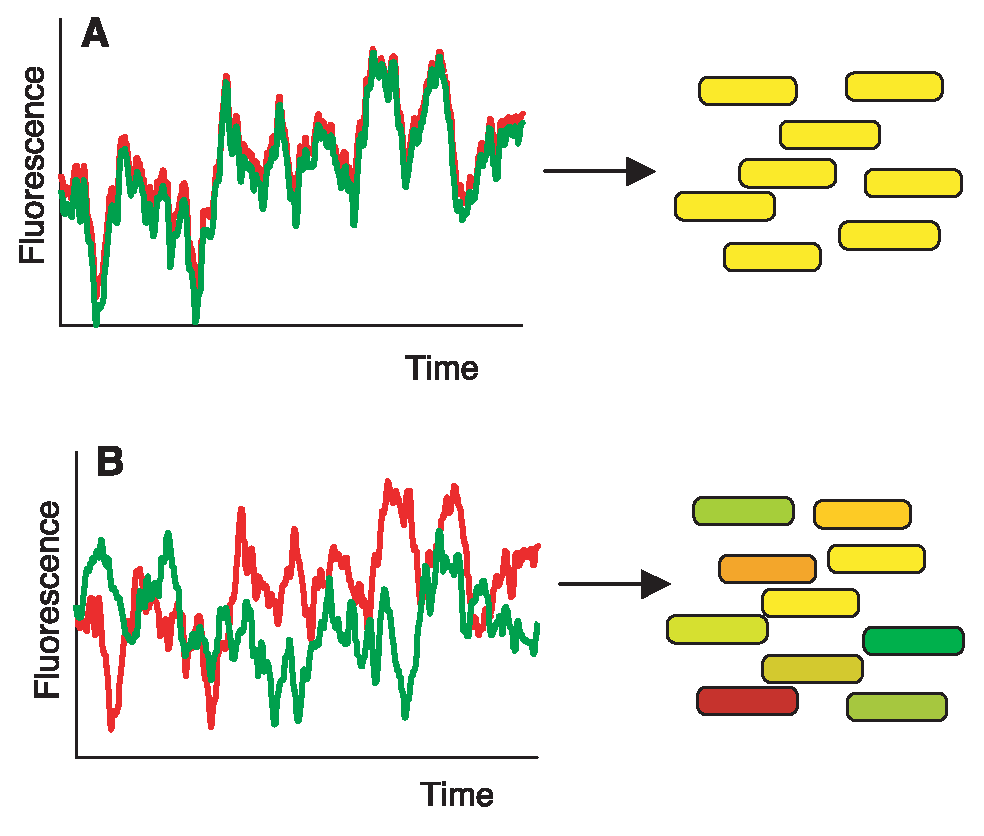

Elowitz et al., Science 297, 1183 (2002), Fig. 1


In [3]:
display(Image("figures/elowitz2002_fig1.png", width=560))
print("Elowitz et al., Science 297, 1183 (2002), Fig. 1")

### Our model of the experiment

**Each colour is the gene of Lecture 1.** CFP is made at rate $\beta$ and removed at rate $\alpha$
per molecule; the same for YFP, with the **same** $\beta$ and $\alpha$ (identical promoters, equally
stable proteins). With nothing else, the two colours are independent copies of the same gene:
this is pure **intrinsic** noise, and each colour is Poisson with mean $\beta/\alpha$ (Lecture 2).

**Extrinsic noise: a shared factor $r$.** In a real cell $\beta$ is not a fixed number: it depends
on how many polymerases, ribosomes or activators the cell has at that moment. We lump all of this
into one molecule, $r$, and make the production rate of *both* colours proportional to it:

$$\text{production of CFP} = \text{production of YFP} = \beta\,\frac{r}{\bar r},$$

where $\bar r$ is the average number of $r$ molecules. When $r = \bar r$ the rate is exactly
$\beta$; when the cell happens to have more $r$, both colours are made faster, together.

**How $r$ itself is made.** The simplest choice: $r$ is one more gene of Lecture 1, made at a
constant rate $\beta_r$ and removed at rate $\alpha_r$ per molecule, so $\bar r = \beta_r/\alpha_r$
and $r$ fluctuates around $\bar r$. Two consequences:

- $\bar r$ sets **how large** the extrinsic noise is: fewer $r$ molecules, larger relative
  fluctuations ($1/\sqrt{\bar r}$, Lecture 2);
- $\alpha_r$ sets **how fast** $r$ changes. We take $\alpha_r = \alpha$.

**Switch.** With `extrinsic=False`, $r$ is held at $\bar r$: the extrinsic noise is off and we are
back to two independent genes of Lecture 1.

Numbers: $\alpha = \alpha_r = 1$ (stable proteins diluted by growth; time is in units of
$1/\alpha$, about a cell cycle), $\beta = 25$, so 25 molecules of each colour on average, and
$\bar r = 25$.

The reactions, in the format of our `gillespie` function, with the species in the order
$(r, c, y)$:

| reaction | change of $(r, c, y)$ | rate |
|---|---|---|
| $r$ made | $(+1, 0, 0)$ | $\beta_r$ |
| $r$ removed | $(-1, 0, 0)$ | $\alpha_r\, r$ |
| CFP made | $(0, +1, 0)$ | $\beta\, r/\bar r$ |
| CFP removed | $(0, -1, 0)$ | $\alpha\, c$ |
| YFP made | $(0, 0, +1)$ | $\beta\, r/\bar r$ |
| YFP removed | $(0, 0, -1)$ | $\alpha\, y$ |

In [4]:
CHANGES_RCY = [(1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1)]

def rates_rcy(x, beta=25.0, r_bar=25.0, alpha=1.0, alpha_r=1.0, extrinsic=True):
    r, c, y = x
    beta_r = alpha_r * r_bar if extrinsic else 0.0     # extrinsic off: r is never made...
    alpha_r = alpha_r if extrinsic else 0.0            # ...nor removed, so it stays at r_bar
    production = beta * r / r_bar                      # the same for both colours
    return [beta_r, alpha_r * r, production, alpha * c, production, alpha * y]

def start(r_bar=25.0):
    '''Initial state: r at its average, no CFP and no YFP yet.'''
    return [round(r_bar), 0, 0]

rng = np.random.default_rng(1)
t = np.linspace(0, 30, 1501)
one_cell = gillespie(start(), CHANGES_RCY, rates_rcy, t, rng)
r, c, y = one_cell.T

### One cell, followed in time

**PREDICT:** will the two colours follow each other closely? Will the cell look yellow all the
time?

To colour the cell we do what the microscope pictures do: YFP goes in the red channel, CFP in the
green channel. Equal amounts give yellow; more YFP gives orange to red; more CFP gives
yellow-green to green.

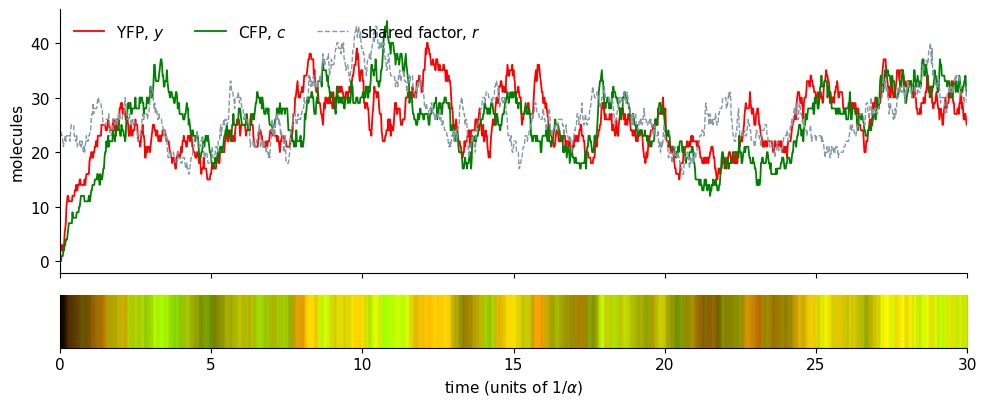

In [5]:
def cell_colour(c, y, scale):
    '''RGB colour of cells with c CFP and y YFP molecules: YFP -> red, CFP -> green.'''
    c, y = np.asarray(c, float), np.asarray(y, float)
    return np.stack([y / scale, c / scale, 0 * c], axis=-1).clip(0, 1)

def colour_strip(ax, t, c, y, scale):
    '''The colour of one cell over time, as a horizontal band.'''
    ax.imshow(cell_colour(c, y, scale)[np.newaxis, :, :], aspect="auto",
              extent=[t[0], t[-1], 0, 1])
    ax.set_yticks([]); ax.set_xlabel("time (units of $1/\\alpha$)")

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 4.2), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 0.6]})
top.plot(t, y, color="red", lw=1.3, label="YFP, $y$")
top.plot(t, c, color="green", lw=1.3, label="CFP, $c$")
top.plot(t, r, color=GREY, lw=1, ls="--", label="shared factor, $r$")
top.set(ylabel="molecules"); top.legend(frameon=False, ncol=3, loc="upper left")
colour_strip(bottom, t, c, y, scale=35)
plt.tight_layout(); plt.show()

The two colours share the slow ups and downs of $r$ (extrinsic), and on top of that each one
wobbles on its own (intrinsic). So the colour of the cell changes over time: mostly yellow, with
moments where it leans to orange or to green. This is Figure 1B of the paper, made by us.

### Many cells, as under the microscope

A picture of many cells is a snapshot: each cell is caught at a random moment of its own history.
We simulate 400 independent cells for 15 units of time (enough to forget the start) and keep the
last values.

**PREDICT:** we take the picture three times, with 10 times less expression ($\beta = 2.5$), as
above ($\beta = 25$), and with 10 times more ($\beta = 250$). Which population looks most uniformly
yellow?

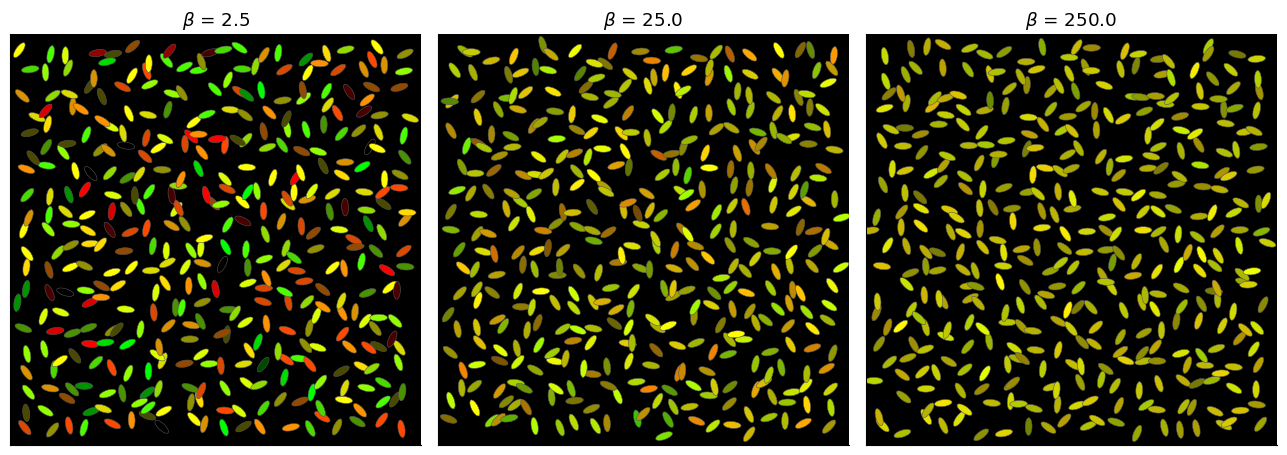

In [6]:
def snapshot(n_cells, rates, x0, changes, t_end, rng):
    '''Numbers of molecules in n_cells independent cells at time t_end.'''
    return np.array([gillespie(x0, changes, rates, [t_end], rng)[0] for _ in range(n_cells)])

def microscope(ax, c, y, scale, rng, title=""):
    '''Draw each cell as a little rod coloured by its CFP (green) and YFP (red).'''
    n = len(c)
    side = int(np.ceil(np.sqrt(n)))
    colours = cell_colour(c, y, scale)
    for i in range(n):
        x0 = (i % side) + 0.25 * rng.standard_normal()
        y0 = (i // side) + 0.25 * rng.standard_normal()
        ax.add_patch(Ellipse((x0, y0), 0.9, 0.35, angle=rng.uniform(0, 180),
                             facecolor=colours[i], edgecolor="#555555", lw=0.4))  # outline: dark cells stay visible
    ax.set(xlim=(-1, side), ylim=(-1, side), title=title, aspect="equal")
    ax.set_facecolor("black"); ax.set_xticks([]); ax.set_yticks([])

rng = np.random.default_rng(2)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, beta in zip(axes, [2.5, 25.0, 250.0]):
    cells = snapshot(400, lambda x, b=beta: rates_rcy(x, beta=b), start(), CHANGES_RCY, 15, rng)
    # like a camera exposure, the brightness is scaled to the average expression
    microscope(ax, cells[:, 1], cells[:, 2], scale=1.4 * beta, rng=rng, title=f"$\\beta$ = {beta}")
plt.tight_layout(); plt.show()

With few molecules ($\beta = 2.5$) many cells are clearly red or green, and some are dark; with
many molecules ($\beta = 250$) almost all are yellow, brighter or dimmer. Compare with the real
thing (Elowitz et al., Fig. 2): in (A) the reporters are repressed and few molecules are made,
in (B) the repressor is switched off (IPTG) and many more are made.

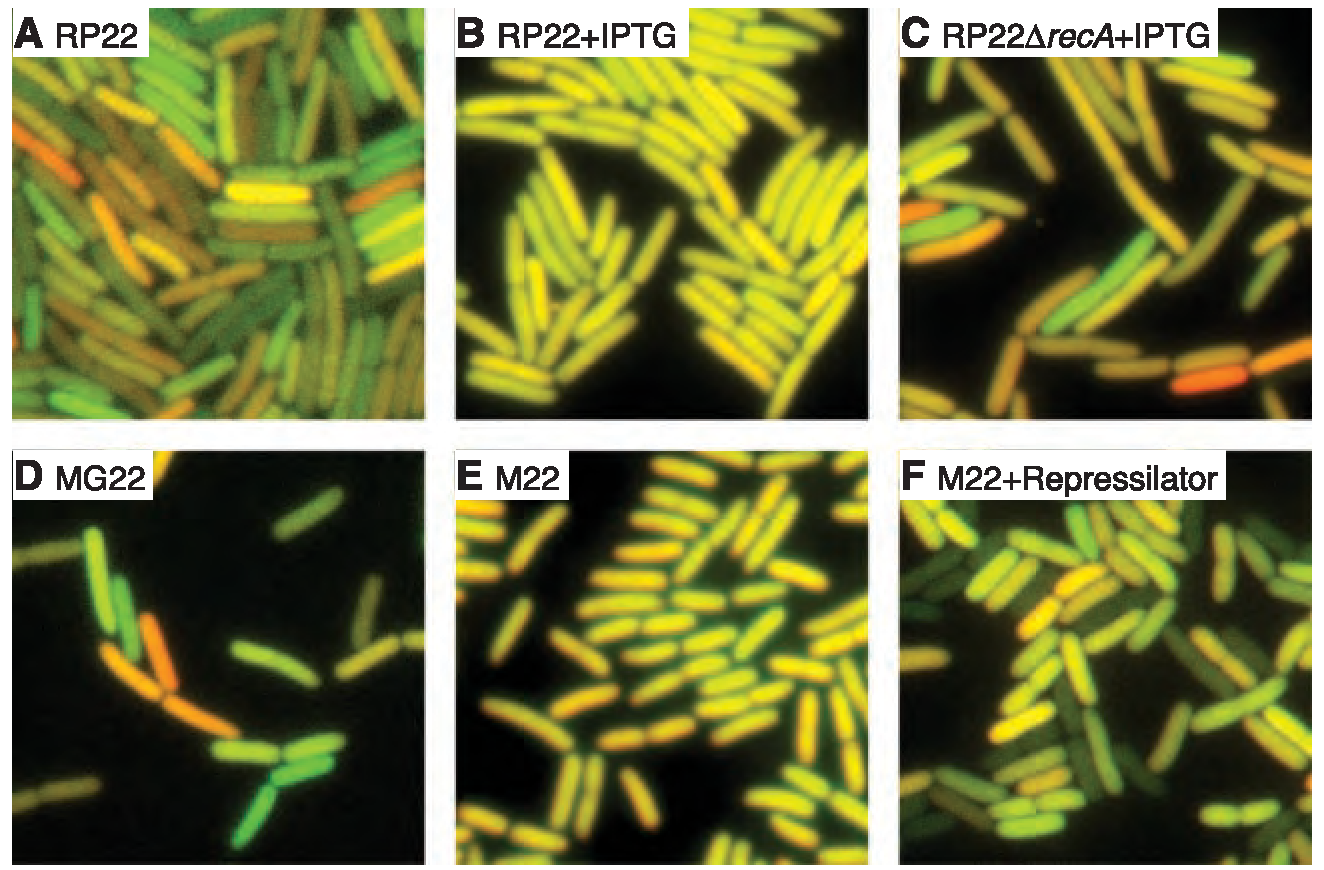

Elowitz et al., Science 297, 1183 (2002), Fig. 2: (A) RP22, (B) RP22 + IPTG, (C) RP22 ΔrecA + IPTG,
(D) MG22, (E) M22, (F) M22 + repressilator


In [7]:
display(Image("figures/elowitz2002_fig2.png", width=640))
print("Elowitz et al., Science 297, 1183 (2002), Fig. 2: (A) RP22, (B) RP22 + IPTG, (C) RP22 ΔrecA + IPTG,")
print("(D) MG22, (E) M22, (F) M22 + repressilator")

### The two directions of the scatter plot

Put every cell on a plot, with its CFP on one axis and its YFP on the other.

- If only **extrinsic** noise were present, every cell would have $c = y$: all points on the
  diagonal, spread **along** it.
- **Intrinsic** noise makes $c$ and $y$ differ in the same cell: it spreads the points
  **across** the diagonal.

**PREDICT:** sketch the cloud of points in three cases: (i) the model as it is; (ii) extrinsic
noise off; (iii) ten times more expression ($\beta = 250$).

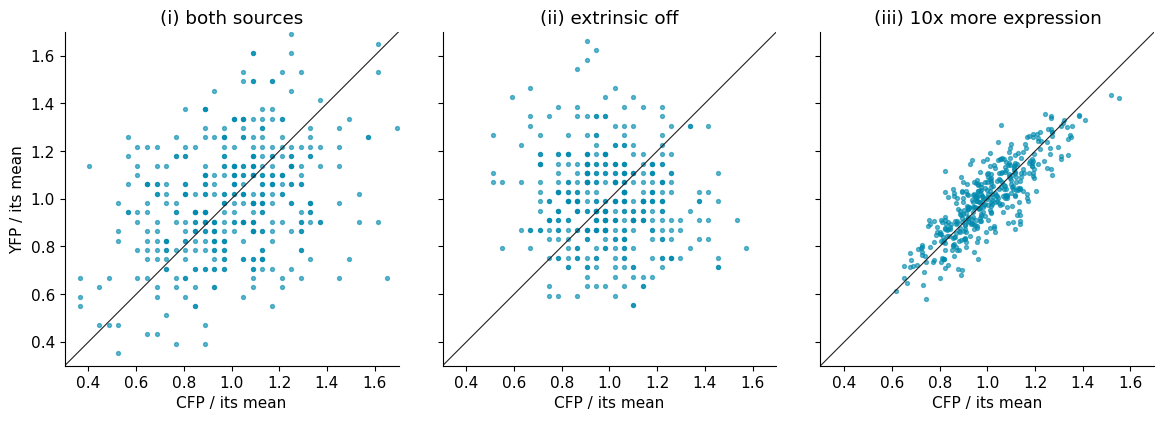

In [8]:
rng = np.random.default_rng(3)
cases = {
    "(i) both sources":         dict(),
    "(ii) extrinsic off":       dict(extrinsic=False),
    "(iii) 10x more expression": dict(beta=250.0),
}
data = {}
for name, options in cases.items():
    data[name] = snapshot(400, lambda x, o=options: rates_rcy(x, **o), start(), CHANGES_RCY, 15, rng)

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (name, cells) in zip(axes, data.items()):
    c, y = cells[:, 1], cells[:, 2]
    ax.scatter(c / c.mean(), y / y.mean(), s=8, color=BLUE, alpha=0.6)
    ax.plot([0, 2], [0, 2], color=INK, lw=0.8)
    ax.set(xlim=(0.3, 1.7), ylim=(0.3, 1.7), aspect="equal", title=name,
           xlabel="CFP / its mean")
axes[0].set_ylabel("YFP / its mean")
plt.tight_layout(); plt.show()

- (i) An elongated cloud, tilted along the diagonal, but thick across it: both sources.
- (ii) Extrinsic noise off: the cloud is round. What is left is the independent noise of each copy.
- (iii) Ten times more molecules: the cloud gets thin across the diagonal but stays just as long
  along it. **More molecules reduce intrinsic noise and leave extrinsic noise alone.**

Compare with Figure 3A of the paper: two strains, one quiet (M22) and one noisy (D22).

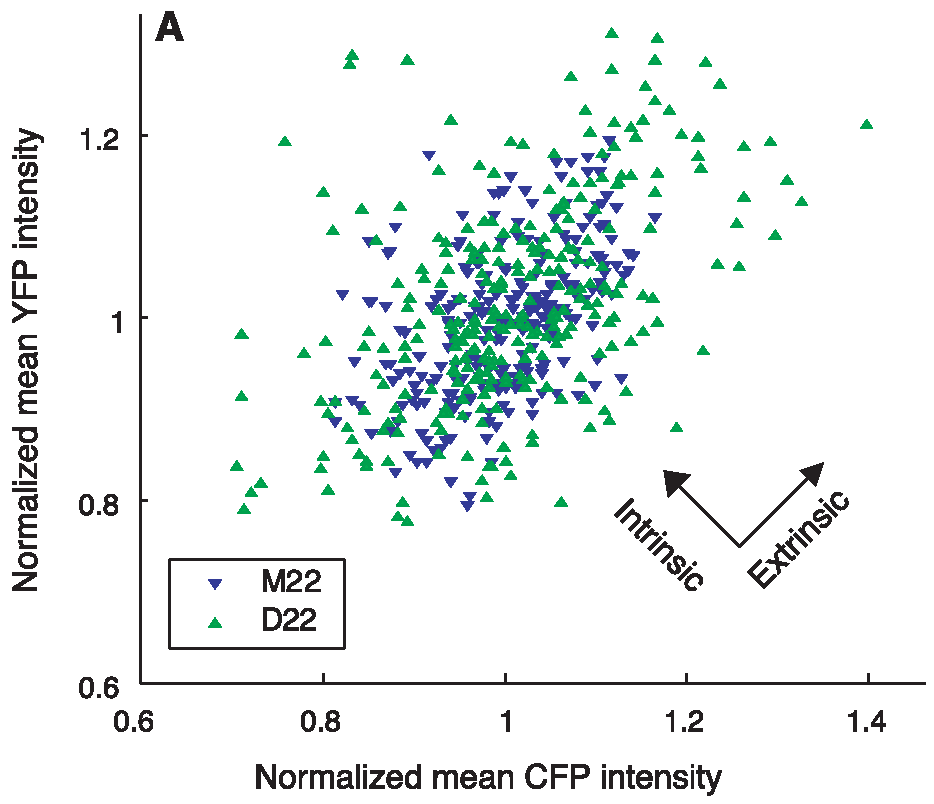

Elowitz et al., Science 297, 1183 (2002), Fig. 3A


In [9]:
display(Image("figures/elowitz2002_fig3A.png", width=430))
print("Elowitz et al., Science 297, 1183 (2002), Fig. 3A")

### Putting numbers on it

We want one number for each direction of the cloud. All three use quantities you know.

**Total noise.** The noise of one colour is its coefficient of variation, $\text{CV} =
\text{standard deviation}/\text{mean}$. Elowitz and colleagues call it $\eta_{\text{tot}}$ and work
with its square:

$$\eta_{\text{tot}}^2 = \frac{\mathrm{Var}(c)}{\langle c\rangle^2}.$$

(The two colours are equivalent, so the code averages over them.)

**Intrinsic noise.** Use the *difference* between the two colours in the same cell. Whatever the
two copies share --- the extrinsic part --- cancels in $c - y$. This is the trick of Lecture 1,
where we used $\langle (I_1 - I_2)^2\rangle$ to get rid of what the two daughters shared:

$$\eta_{\text{int}}^2 = \frac{\langle (c - y)^2\rangle}{2\,\langle c\rangle \langle y\rangle}.$$

The 2 is there because $c$ and $y$ are two independent copies, and the variance of a difference of
two independent quantities is the sum of their variances.

**Extrinsic noise: what is left.**

$$\eta_{\text{ext}}^2 = \eta_{\text{tot}}^2 - \eta_{\text{int}}^2 .$$

In words: the extrinsic part measures how much the two colours go up and down **together** from
cell to cell. This is the relation $\eta_{\text{tot}}^2 = \eta_{\text{int}}^2 +
\eta_{\text{ext}}^2$ quoted in the paper.

> **A name you may meet.** "How much two quantities go up and down together" is called the
> **covariance**, $\mathrm{cov}(c, y) = \langle (c - \langle c\rangle)(y - \langle y\rangle)\rangle$.
> It is positive when $c$ tends to be above its mean in the same cells where $y$ is above its
> mean, and zero when the two are independent. The paper writes
> $\eta_{\text{ext}}^2 = \mathrm{cov}(c,y)/(\langle c\rangle\langle y\rangle)$, which is the same
> as our "what is left". We will not need the word again.

In [10]:
def noise(c, y):
    '''(eta_int, eta_ext, eta_tot) of a population, from its CFP and YFP numbers.'''
    c, y = np.asarray(c, float), np.asarray(y, float)
    mc, my = c.mean(), y.mean()
    eta_tot2 = (c.var() / mc**2 + y.var() / my**2) / 2     # CV^2, averaged over the two colours
    eta_int2 = np.mean((c - y)**2) / (2 * mc * my)
    eta_ext2 = eta_tot2 - eta_int2                           # what is left
    return np.sqrt(eta_int2), np.sqrt(max(eta_ext2, 0)), np.sqrt(eta_tot2)

print(f"{'case':28s} {'mean c':>7s} {'eta_int':>8s} {'eta_ext':>8s} {'eta_tot':>8s}   1/sqrt(mean c)")
for name, cells in data.items():
    c, y = cells[:, 1], cells[:, 2]
    e_int, e_ext, e_tot = noise(c, y)
    print(f"{name:28s} {c.mean():7.1f} {e_int:8.3f} {e_ext:8.3f} {e_tot:8.3f}   {1/np.sqrt(c.mean()):.3f}")

case                          mean c  eta_int  eta_ext  eta_tot   1/sqrt(mean c)
(i) both sources                24.8    0.199    0.148    0.248   0.201
(ii) extrinsic off              25.4    0.197    0.000    0.190   0.198
(iii) 10x more expression      248.7    0.063    0.144    0.157   0.063


Three things to notice.

- **The intrinsic noise is $1/\sqrt{\langle c\rangle}$.** That is the Poisson result of Lecture 2:
  variance = mean, so $\text{CV}^2 = 1/\text{mean}$.
- **Ten times more expression divides $\eta_{\text{int}}^2$ by ten and leaves $\eta_{\text{ext}}$
  as it was.**
- **With extrinsic noise off, $\eta_{\text{ext}}$ should be exactly 0.** We do not get exactly 0,
  because $\eta_{\text{ext}}^2$ is the difference of two numbers measured on 400 cells, and every
  number measured on a finite sample carries a small error. The difference can even come out
  slightly **negative**, which no real $\eta^2$ can be; the code then prints 0.

The cell below repeats case (ii) three times for each population size and prints
$\eta_{\text{ext}}^2$ with its sign: the values scatter around 0, less and less as the number of
cells grows.

In [11]:
rng = np.random.default_rng(8)
for n_cells in [100, 400, 1600]:
    estimates = []
    for repeat in range(3):
        cells = snapshot(n_cells, lambda x: rates_rcy(x, extrinsic=False), start(), CHANGES_RCY, 15, rng)
        c, y = cells[:, 1].astype(float), cells[:, 2].astype(float)
        eta_tot2 = (c.var() / c.mean()**2 + y.var() / y.mean()**2) / 2
        eta_int2 = np.mean((c - y)**2) / (2 * c.mean() * y.mean())
        estimates.append(eta_tot2 - eta_int2)
    print(f"extrinsic off, {n_cells:4d} cells: eta_ext^2 = " + ", ".join(f"{e:+.4f}" for e in estimates)
          + f"   (compare eta_int^2 = {eta_int2:.3f})")

extrinsic off,  100 cells: eta_ext^2 = -0.0066, +0.0040, -0.0055   (compare eta_int^2 = 0.049)


extrinsic off,  400 cells: eta_ext^2 = +0.0038, -0.0020, -0.0010   (compare eta_int^2 = 0.043)


extrinsic off, 1600 cells: eta_ext^2 = -0.0006, +0.0004, +0.0011   (compare eta_int^2 = 0.038)


### Two knobs: one for each kind of noise

In the model we can turn the two sources separately.

- **The intrinsic knob is $\beta$**, the expression level: it sets how many molecules of each
  colour there are, and $\eta_{\text{int}} = 1/\sqrt{\langle c\rangle}$.
- **The extrinsic knob is $\bar r$**, how many molecules of the shared factor there are: fewer
  $r$ molecules, larger fluctuations of $r$, and both colours follow them.

**PREDICT:** (1) $\beta$ goes from 5 to 200 with $\bar r = 25$; (2) $\bar r$ goes from 4 to 256
with $\beta = 25$. In each case, which of $\eta_{\text{int}}$ and $\eta_{\text{ext}}$ changes?

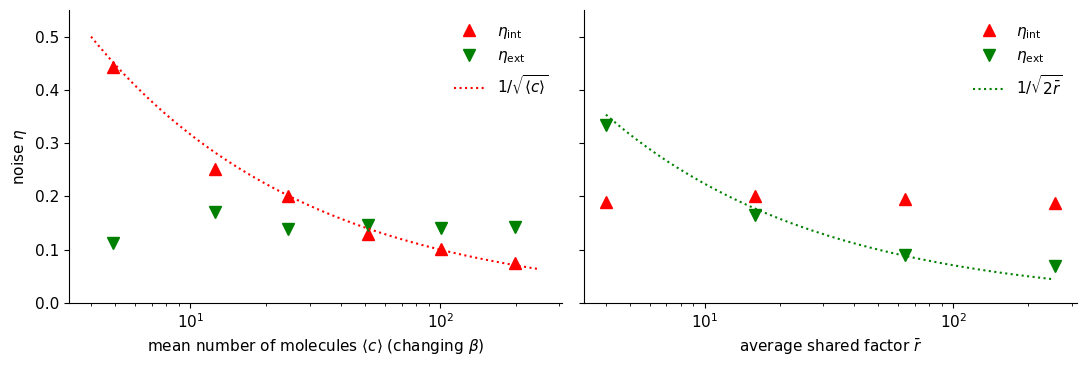

changing beta: mean c =    4.9, eta_int = 0.443 (1/sqrt = 0.451), eta_ext = 0.113
changing beta: mean c =   12.6, eta_int = 0.252 (1/sqrt = 0.282), eta_ext = 0.171
changing beta: mean c =   24.6, eta_int = 0.200 (1/sqrt = 0.202), eta_ext = 0.138
changing beta: mean c =   51.2, eta_int = 0.129 (1/sqrt = 0.140), eta_ext = 0.147
changing beta: mean c =  100.6, eta_int = 0.101 (1/sqrt = 0.100), eta_ext = 0.141
changing beta: mean c =  199.3, eta_int = 0.075 (1/sqrt = 0.071), eta_ext = 0.143
changing r_bar: r_bar =    4, eta_int = 0.189, eta_ext = 0.333
changing r_bar: r_bar =   16, eta_int = 0.200, eta_ext = 0.165
changing r_bar: r_bar =   64, eta_int = 0.195, eta_ext = 0.090
changing r_bar: r_bar =  256, eta_int = 0.187, eta_ext = 0.070


In [12]:
rng = np.random.default_rng(4)
scan_beta, scan_rbar = [], []
for beta in [5, 12.5, 25, 50, 100, 200]:
    cells = snapshot(300, lambda x, b=beta: rates_rcy(x, beta=b), start(), CHANGES_RCY, 15, rng)
    scan_beta.append((cells[:, 1].mean(),) + noise(cells[:, 1], cells[:, 2])[:2])
for r_bar in [4, 16, 64, 256]:
    cells = snapshot(300, lambda x, rb=r_bar: rates_rcy(x, r_bar=rb), start(r_bar), CHANGES_RCY, 15, rng)
    scan_rbar.append((r_bar,) + noise(cells[:, 1], cells[:, 2])[:2])

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, scan, xlabel in [(left, scan_beta, r"mean number of molecules $\langle c\rangle$ (changing $\beta$)"),
                         (right, scan_rbar, r"average shared factor $\bar r$")]:
    x, e_int, e_ext = np.array(scan).T
    ax.plot(x, e_int, "^", color="red", ms=8, label=r"$\eta_{\mathrm{int}}$")
    ax.plot(x, e_ext, "v", color="green", ms=8, label=r"$\eta_{\mathrm{ext}}$")
    ax.set(xscale="log", xlabel=xlabel)
m = np.geomspace(4, 250, 100)
left.plot(m, 1 / np.sqrt(m), ":", color="red", label=r"$1/\sqrt{\langle c\rangle}$")
left.set(ylabel=r"noise $\eta$", ylim=(0, 0.55)); left.legend(frameon=False)
rb = np.geomspace(4, 256, 100)
right.plot(rb, 1 / np.sqrt(2 * rb), ":", color="green", label=r"$1/\sqrt{2\bar r}$")
right.legend(frameon=False)
plt.tight_layout(); plt.show()

for (m_c, e_int, e_ext) in scan_beta:
    print(f"changing beta: mean c = {m_c:6.1f}, eta_int = {e_int:.3f} (1/sqrt = {1/np.sqrt(m_c):.3f}), eta_ext = {e_ext:.3f}")
for (r_bar, e_int, e_ext) in scan_rbar:
    print(f"changing r_bar: r_bar = {r_bar:4d}, eta_int = {e_int:.3f}, eta_ext = {e_ext:.3f}")

Each knob moves only its own noise: $\beta$ moves $\eta_{\text{int}}$ along the
$1/\sqrt{\langle c\rangle}$ curve, $\bar r$ moves $\eta_{\text{ext}}$ and leaves
$\eta_{\text{int}}$ near $1/\sqrt{25} = 0.2$. (The dotted curve on the right,
$\eta_{\text{ext}} = 1/\sqrt{2\bar r}$, is what this model gives when $\alpha_r = \alpha$; we
do not derive it. The last point lies above it because with 300 cells the estimate of a small
$\eta_{\text{ext}}$ is not precise, as seen just above.)

In the experiment Elowitz and colleagues had only one knob, the inducer IPTG, and it moved
**both** noises (Fig. 3B below, where the x axis is the expression level). The intrinsic noise
follows $\eta_{\text{int}}^2 \approx c_1/m + c_2$, with $m$ the fluorescence: the term $c_1/m$ is
our $1/\langle c\rangle$. The extrinsic noise also changes, because IPTG acts through the
repressor LacI, whose amount differs from cell to cell.

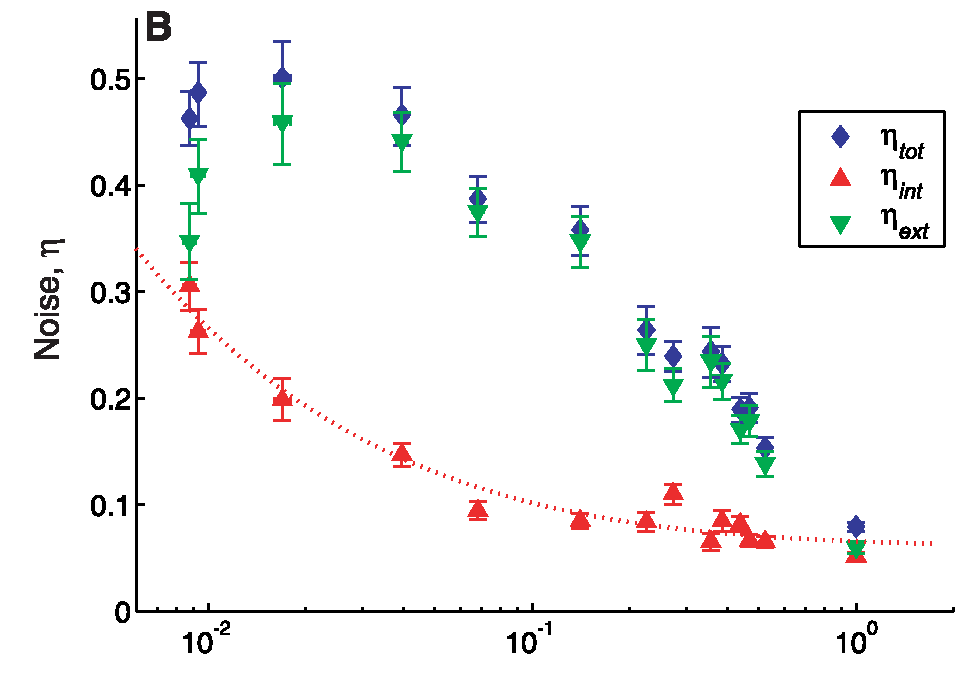

Elowitz et al., Science 297, 1183 (2002), Fig. 3B (x axis: fluorescence relative to the fully induced strain)


In [13]:
display(Image("figures/elowitz2002_fig3B.png", width=430))
print("Elowitz et al., Science 297, 1183 (2002), Fig. 3B (x axis: fluorescence relative to the fully induced strain)")

**What the numbers in the paper say** (Table 1): with strong constitutive promoters,
$\eta_{\text{int}} \approx 0.05$ and $\eta_{\text{tot}} \approx 0.08$; with the reporters
repressed (3 to 6% of the protein), both intrinsic and extrinsic noise go up by about a factor
5 (for instance $\eta_{\text{int}} = 0.25$, $\eta_{\text{ext}} = 0.33$ in strain RP22). Both
sources matter, and which one dominates depends on the conditions.

> **The extrinsic noise of one gene is the intrinsic noise of another.** In our model $r$ is itself
> a gene of Lecture 1 with its own Poisson noise. Seen from CFP and YFP, the fluctuations of $r$ are
> extrinsic; seen from $r$, they are intrinsic.

---
## 2. A switch with noise

### The gene of Lecture 3, one molecule at a time

Take the self-activating gene of Lecture 3 with the signal held at $s = 0.15$:

$$\frac{dX}{dt} = \underbrace{0.05 + 0.15}_{\beta_0 + s} + \frac{2\,X^4}{1 + X^4} - X .$$

It has three fixed points: low (stable), middle (unstable: the threshold), high (stable).

In [14]:
def f_switch(X, basal=0.2, beta=2.0, K=1.0, n=4):
    '''Production of the Lecture 3 gene with the signal held at s = 0.15 (basal = 0.05 + 0.15).'''
    return basal + beta * X**n / (K**n + X**n)

g = lambda X: f_switch(X) - X
grid = np.linspace(0, 4, 40001)
values = g(grid)
X_low, X_mid, X_high = [brentq(g, grid[i], grid[i + 1])
                        for i in range(len(grid) - 1) if values[i] * values[i + 1] < 0]
print(f"fixed points: low {X_low:.3f} (stable), middle {X_mid:.3f} (unstable), high {X_high:.3f} (stable)")

fixed points: low 0.203 (stable), middle 0.818 (unstable), high 2.103 (stable)


In a cell, the concentration $X$ is made of $N = V X$ molecules. The two reactions are
production, $N \to N+1$ at rate $V f(N/V)$, and removal, $N \to N - 1$ at rate
$\alpha N$ with $\alpha = 1$. With $V = 10$ the low state has about 2 molecules and the high
state about 21.

**PREDICT:** a cell starts in the low state. In the deterministic picture of Lecture 3 it stays
there for ever. What will the stochastic cell do over 1000 units of time? And what will the
histogram of $X$ look like?

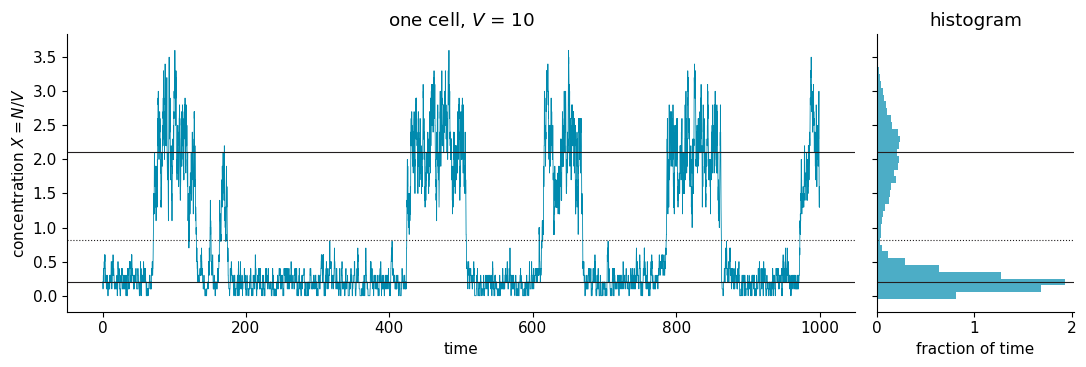

fraction of time above the threshold: 0.32


In [15]:
CHANGES_N = [(1,), (-1,)]

def rates_switch(x, V):
    N = x[0]
    return [V * f_switch(N / V), 1.0 * N]

rng = np.random.default_rng(5)
V = 10
t = np.arange(0, 1000, 0.1)
X = gillespie([round(V * X_low)], CHANGES_N, lambda x: rates_switch(x, V), t, rng)[:, 0] / V

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True,
                                  gridspec_kw={"width_ratios": [4, 1]})
left.plot(t, X, color=BLUE, lw=0.6)
for level, style in [(X_low, "-"), (X_mid, ":"), (X_high, "-")]:
    left.axhline(level, color=INK, lw=0.8, ls=style)
    right.axhline(level, color=INK, lw=0.8, ls=style)
left.set(xlabel="time", ylabel="concentration $X = N/V$", title=f"one cell, $V$ = {V}")
right.hist(X, bins=np.arange(-0.05, X.max() + 0.1, 1 / V), orientation="horizontal",
           density=True, color=BLUE, alpha=0.7)
right.set(xlabel="fraction of time", title="histogram")
plt.tight_layout(); plt.show()
print(f"fraction of time above the threshold: {np.mean(X > X_mid):.2f}")

- The cell **jumps** between the two states. It spends a long time near one stable point
  (solid lines), and from time to time noise pushes it over the threshold (dotted line) and it
  runs to the other one.
- The histogram has **two peaks**, at the two stable points, and a valley at the threshold. A
  population of such cells, observed at one moment, would be **bimodal**: identical cells, two
  kinds of behaviour.

The memory of Lecture 3 is still there, but it is no longer for ever: it lasts a *typical
time*. Back to the rate plot: to leave the low state, noise must push $X$ from 0.203 up to the
threshold 0.818, against the arrows; to leave the high state, from 2.103 down to 0.818.

### How long does the memory last?

**What we measure.** We follow one cell for a long time and cut its trajectory into **stays**: a
stay in OFF starts when the cell arrives at the low stable point and ends when it reaches the high
one; a stay in ON is the opposite. (We wait until the cell actually *reaches* the other stable
point, so that a short excursion towards the threshold is not counted as a switch.) The average
length of a stay is the **lifetime of the memory** in that state.

**What we change.** The volume of the cell, $V = 5$, 10, 15. The concentrations of the two stable
states do not change, but the numbers of molecules do: about 1, 2, 3 molecules in OFF and 11, 21,
32 in ON.

**PREDICT:** in a larger cell, more molecules: do the stays get longer or shorter?

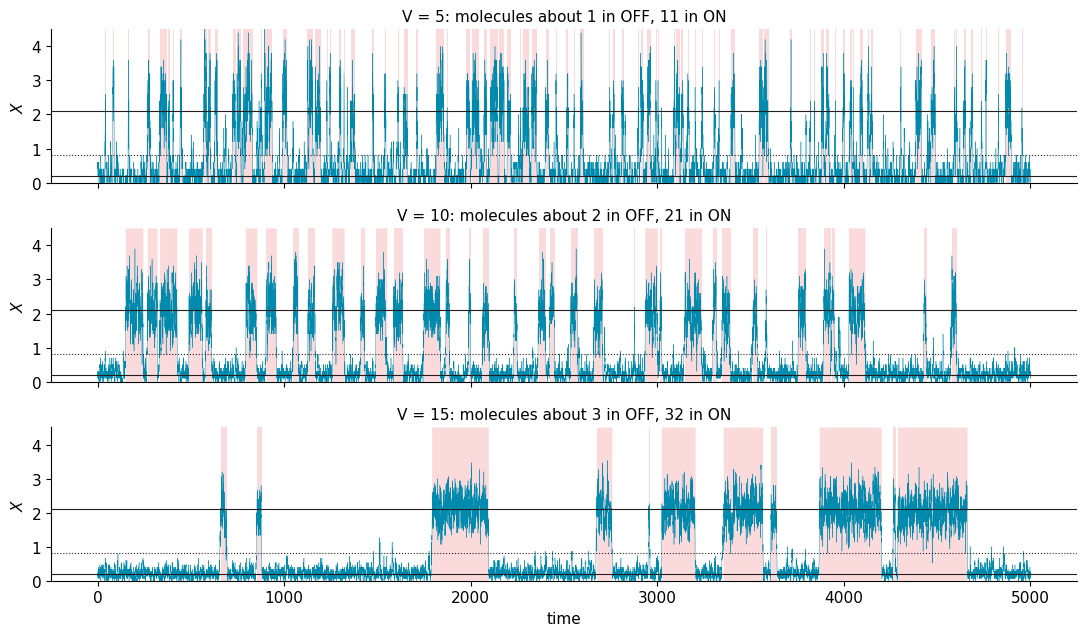

In [16]:
def stays(X, t, low, high):
    '''Lengths of the stays in OFF and in ON. A stay ends when X reaches the other stable point.'''
    state = "OFF" if X[0] < (low + high) / 2 else "ON"
    t_start = None
    result = {"OFF": [], "ON": []}
    for xi, ti in zip(X, t):
        if (state == "OFF" and xi >= high) or (state == "ON" and xi <= low):
            if t_start is not None:                # the first stay is cut by the start: skip it
                result[state].append(ti - t_start)
            state = "ON" if state == "OFF" else "OFF"
            t_start = ti
    return result

rng = np.random.default_rng(6)
runs = {}
for V, t_end in [(5, 5000), (10, 20000), (15, 60000)]:      # longer runs where switches are rarer
    t = np.arange(0, t_end, 0.1)
    X = gillespie([round(V * X_low)], CHANGES_N, lambda x: rates_switch(x, V), t, rng)[:, 0] / V
    runs[V] = (t, X)

def state_in_time(X, low, high):
    '''1 while the cell is in a stay in ON, 0 while in OFF (same rule as stays()).'''
    state = 0 if X[0] < (low + high) / 2 else 1
    out = np.empty(len(X), dtype=int)
    for i, xi in enumerate(X):
        if state == 0 and xi >= high:
            state = 1
        elif state == 1 and xi <= low:
            state = 0
        out[i] = state
    return out

# the first 5000 time units of each run; the stays in ON are shaded
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True, sharey=True)
for ax, (V, (t, X)) in zip(axes, runs.items()):
    window = t < 5000
    on = state_in_time(X, X_low, X_high)[window]
    ax.fill_between(t[window], 0, 4.5, where=on == 1, color=CORAL, alpha=0.25, lw=0)
    ax.plot(t[window], X[window], color=BLUE, lw=0.3)
    for level, style in [(X_low, "-"), (X_mid, ":"), (X_high, "-")]:
        ax.axhline(level, color=INK, lw=0.8, ls=style)
    ax.set_title(f"V = {V}: molecules about {V*X_low:.0f} in OFF, {V*X_high:.0f} in ON", fontsize=11)
    ax.set(ylabel="$X$", ylim=(0, 4.5))
axes[-1].set_xlabel("time")
plt.tight_layout(); plt.show()

The same switch, three cell sizes, over the same 5000 units of time; the shaded intervals are the
stays in ON. The larger the cell, the rarer the jumps, and the longer both kinds of stay. Now the numbers,
measured over the whole runs. The larger cells were simulated for longer (5000, 20000 and 60000
units of time), so that every average is taken over at least 180 stays; to compare the three
cells fairly we therefore count the switches **per 1000 units of time**. (Do not read the averages off
a short piece of trajectory: the stays are random, some much longer than the average and some
much shorter, and a window of a few thousand time units holds only a handful of them when the cell
is large.)

  V   molecules OFF / ON   switches per 1000 time units   average stay in OFF   average stay in ON
  5           1 / 11                   36.6                       40                   14
 10           2 / 21                   14.2                       95                   43
 15           3 / 32                    6.3                      214                  102


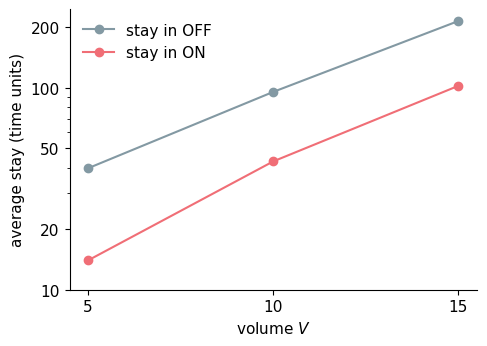

In [17]:
mean_off, mean_on = [], []
print("  V   molecules OFF / ON   switches per 1000 time units   average stay in OFF   average stay in ON")
for V, (t, X) in runs.items():
    s = stays(X, t, X_low, X_high)
    n_switches = len(s["OFF"]) + len(s["ON"])
    mean_off.append(np.mean(s["OFF"])); mean_on.append(np.mean(s["ON"]))
    print(f"{V:3d}   {V*X_low:9.0f} / {V*X_high:<5.0f}  {1000 * n_switches / t[-1]:18.1f}   "
          f"{mean_off[-1]:22.0f}   {mean_on[-1]:18.0f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
Vs = list(runs)
ax.plot(Vs, mean_off, "o-", color=GREY, label="stay in OFF")
ax.plot(Vs, mean_on, "o-", color=CORAL, label="stay in ON")
ax.set(yscale="log", xlabel="volume $V$", ylabel="average stay (time units)", xticks=Vs,
       yticks=[10, 20, 50, 100, 200], yticklabels=["10", "20", "50", "100", "200"])
ax.legend(frameon=False); plt.tight_layout(); plt.show()

- Time is in units of $1/\alpha$, about one cell cycle for a stable protein. With $V = 10$ a cell
  stays OFF for about a hundred cell cycles before switching on.
- Each step of 5 in $V$ makes the stays 2 to 3 times longer, and on the log scale the points lie
  close to a straight line. Extrapolating, a cell with hundreds of molecules would essentially never
  switch: the deterministic picture of Lecture 3, memory for ever, is the limit of many molecules.

**Noise turns a perfect memory into a memory with a finite lifetime, and the lifetime is set by
the number of molecules.**

### What do the two colours show?

**The question.** A population of cells has split into OFF and ON. Did each **cell** take one
decision, valid for all its genes, or did each **gene** decide on its own? We answer with the
two reporters of Section 1, in two circuits:

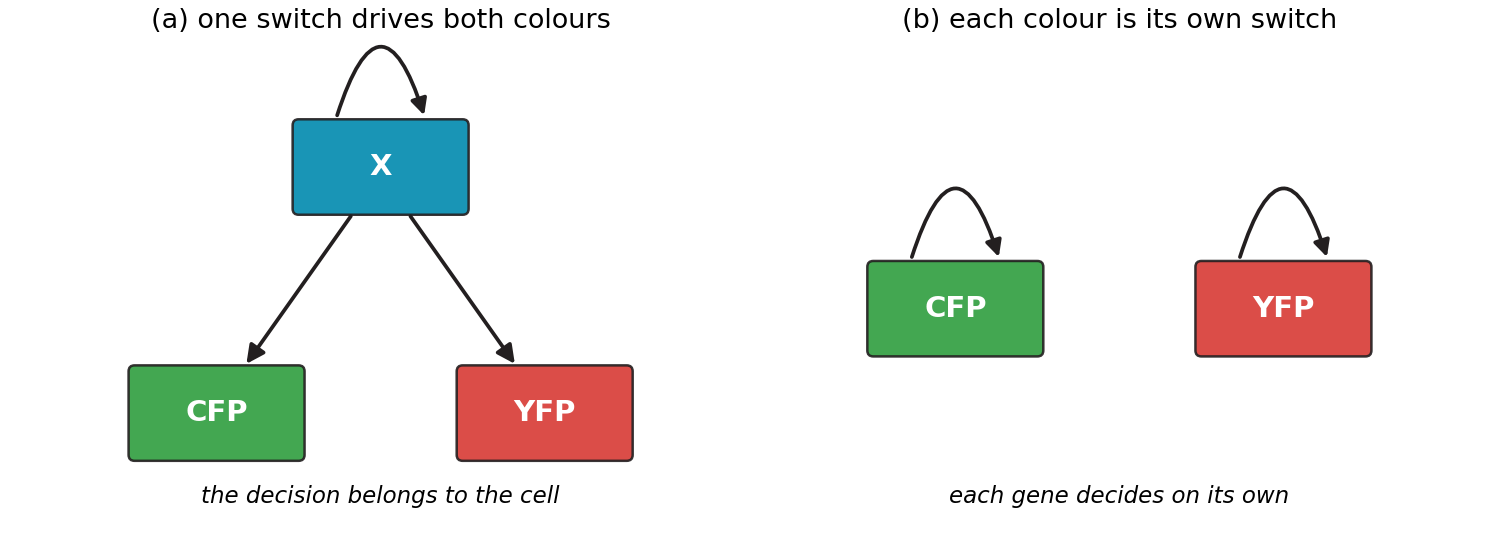

In [18]:
display(Image("figures/fig_two_circuits.png", width=640))

- **(a) One switch, two reporters.** The switch $X$ of this section activates both reporter
  genes: CFP and YFP are each made at rate $\beta_{\text{rep}} X$ (with $\beta_{\text{rep}} = 20$)
  and removed at rate $\alpha = 1$. The switch plays the role that $r$ played in Section 1.
- **(b) Each colour is its own switch.** CFP activates its own gene, and so does YFP, each with
  the same production function as $X$. There is no link between the two. (This is a made-up
  circuit, but one could build it.)

**What we do.** 400 cells per circuit, all started OFF, with $V = 10$; a snapshot at $t = 100$,
when about 30% of the switches have turned on. We look at the cells under the microscope and
in the CFP-YFP plot.

**PREDICT:** for (a) and for (b), which colours will the cells have? Where will the points fall in
the CFP-YFP plot?

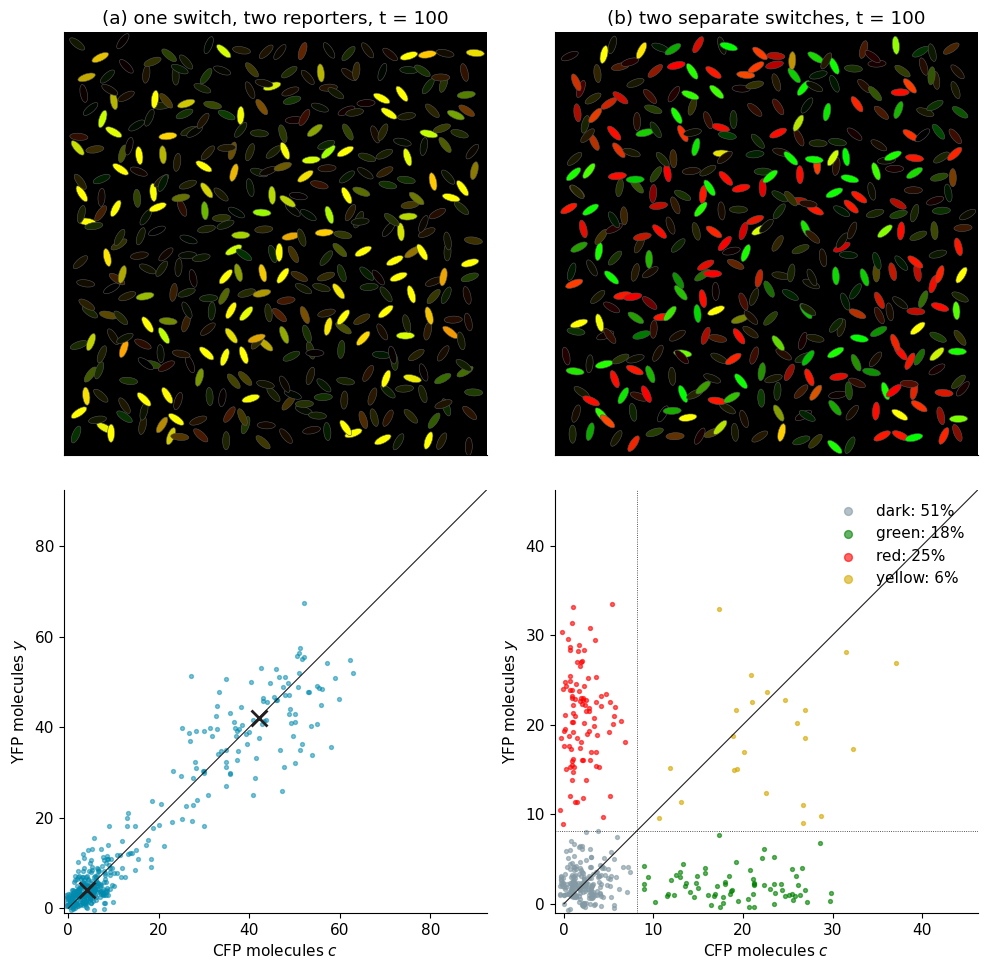

In [19]:
V, beta_rep = 10, 20.0

# (a) one switch X drives both reporters:   X+1  X-1      c+1        c-1        y+1        y-1
CHANGES_A = [(1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1)]
def rates_a(x):
    N, c, y = x
    return [V * f_switch(N / V), N, beta_rep * N / V, c, beta_rep * N / V, y]

# (b) each colour is its own switch:        c+1     c-1      y+1      y-1
CHANGES_B = [(1, 0), (-1, 0), (0, 1), (0, -1)]
def rates_b(x):
    c, y = x
    return [V * f_switch(c / V), c, V * f_switch(y / V), y]

rng = np.random.default_rng(7)
N0 = round(V * X_low)
cells_a = snapshot(400, rates_a, [N0, round(beta_rep * X_low), round(beta_rep * X_low)], CHANGES_A, 100, rng)
cells_b = snapshot(400, rates_b, [N0, N0], CHANGES_B, 100, rng)
c_a, y_a = cells_a[:, 1], cells_a[:, 2]
c_b, y_b = cells_b[:, 0], cells_b[:, 1]

# a colour is "on" when it is above the threshold of its switch
mid_a, mid_b = beta_rep * X_mid, V * X_mid
group_colours = {"dark": GREY, "green": "green", "red": "red", "yellow": "#D4A900"}

def groups(c, y, mid):
    '''The four kinds of cell, from which of the two colours is above the threshold.'''
    return {"dark":  (c <= mid) & (y <= mid), "green":  (c > mid) & (y <= mid),
            "red":   (c <= mid) & (y > mid),  "yellow": (c > mid) & (y > mid)}

def show_two_circuits(c_a, y_a, c_b, y_b, t_snap, rng):
    '''Microscope pictures (top) and CFP-YFP plots (bottom) for circuits (a) and (b).'''
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))
    microscope(axes[0, 0], c_a, y_a, scale=beta_rep * X_high, rng=rng,
               title=f"(a) one switch, two reporters, t = {t_snap}")
    microscope(axes[0, 1], c_b, y_b, scale=V * X_high, rng=rng,
               title=f"(b) two separate switches, t = {t_snap}")
    for ax, c, y, top in [(axes[1, 0], c_a, y_a, 2.2 * beta_rep * X_high),
                          (axes[1, 1], c_b, y_b, 2.2 * V * X_high)]:
        # a small random shift, so that cells with the same integer numbers do not hide each other
        c_shift, y_shift = c + 0.3 * rng.standard_normal(len(c)), y + 0.3 * rng.standard_normal(len(y))
        if c is c_b:                       # (b): colour each point by its group
            for name, members in groups(c_b, y_b, mid_b).items():
                ax.scatter(c_shift[members], y_shift[members], s=8, color=group_colours[name],
                           alpha=0.6, label=f"{name}: {np.mean(members):.0%}")
            ax.axvline(mid_b, color=INK, lw=0.6, ls=":"); ax.axhline(mid_b, color=INK, lw=0.6, ls=":")
            ax.legend(frameon=False, loc="upper right", markerscale=2)
        else:
            ax.scatter(c_shift, y_shift, s=8, color=BLUE, alpha=0.5)
            # where the two clouds should sit: the reporters at steady state with X at a stable point
            for X_star in (X_low, X_high):
                ax.plot(beta_rep * X_star, beta_rep * X_star, "x", color=INK, ms=12, mew=2)
        ax.plot([0, top], [0, top], color=INK, lw=0.8)
        ax.set(xlim=(-1, top), ylim=(-1, top), aspect="equal",
               xlabel="CFP molecules $c$", ylabel="YFP molecules $y$")
    plt.tight_layout(); plt.show()

show_two_circuits(c_a, y_a, c_b, y_b, 100, rng)

**Independent does not mean four equal groups.** In (b) each switch is on with some probability
$p$ (about 0.3 here, since at $t = 100$ about 30% of the switches have turned on). If the two
switches are independent, the four kinds of cell appear with probabilities

| | YFP off | YFP on |
|---|---|---|
| **CFP off** | dark: $(1-p)^2 \approx 0.5$ | red: $p(1-p) \approx 0.2$ |
| **CFP on** | green: $p(1-p) \approx 0.2$ | yellow: $p^2 \approx 0.1$ |

So half the cells are dark, and yellow cells are rare: both switches must be on at once. Under the
microscope the dark cells are hard to see, and the eye is caught by the bright red and green ones.
The test of independence is whether the measured fractions match this table.

In [20]:
on_a = c_a + y_a > 2 * mid_a
print(f"(a) dark: {np.mean(~on_a):.2f}   yellow: {np.mean(on_a):.2f}")
cb_on, yb_on = c_b > mid_b, y_b > mid_b
print(f"(b) dark: {np.mean(~cb_on & ~yb_on):.2f}   green only: {np.mean(cb_on & ~yb_on):.2f}   "
      f"red only: {np.mean(~cb_on & yb_on):.2f}   yellow: {np.mean(cb_on & yb_on):.2f}")
p = np.mean(np.concatenate([cb_on, yb_on]))
print(f"    independent switches, each on with p = {p:.2f}:  "
      f"dark {(1-p)**2:.2f}, green {p*(1-p):.2f}, red {p*(1-p):.2f}, yellow {p*p:.2f}")
print()
for name, c, y in [("(a)", c_a, y_a), ("(b)", c_b, y_b)]:
    e_int, e_ext, e_tot = noise(c, y)
    print(f"{name}: eta_int = {e_int:.2f}, eta_ext = {e_ext:.2f}")

(a) dark: 0.70   yellow: 0.29
(b) dark: 0.51   green only: 0.18   red only: 0.25   yellow: 0.06
    independent switches, each on with p = 0.27:  dark 0.53, green 0.20, red 0.20, yellow 0.07

(a): eta_int = 0.25, eta_ext = 1.12
(b): eta_int = 1.27, eta_ext = 0.00


- **(a) One switch, two reporters.** $X$ is bistable, so we expect **two clouds on the
  diagonal**, and that is what we see: dark cells and yellow cells. The crosses mark where the
  clouds should sit, $c = y = \beta_{\text{rep}} X^*$ with $X^*$ the low (0.203) or high (2.103)
  stable point: about 4 and 42 molecules. The two colours always agree, because they read the same
  switch. Each cloud is stretched *along* the diagonal, because $X$ also wobbles inside each state;
  the few points between the clouds are cells caught while switching (the reporters need a time of
  order $1/\alpha$ to follow $X$). For the reporters, the bimodality of $X$ is **extrinsic** noise,
  and the numbers say so: $\eta_{\text{ext}}$ is large, $\eta_{\text{int}}$ much smaller.
- **(b) Two separate switches.** Four kinds of cells: dark, green, red and yellow, in the
  proportions of the table above, as expected for independent switches (yellow is rare because it
  needs both switches on). Each copy's own noise has been **amplified** by
  its feedback into an all-or-none difference: intrinsic noise made huge. $\eta_{\text{ext}}$ is
  zero within the statistical error: the two switches share nothing. Something similar is seen in
  Fig. 2F of the paper, where the reporters are driven by an oscillator (the repressilator) and the cells come in all colours.

The two-colour experiment answers the question at a glance: **does the decision belong to the
cell, or to each gene?**

### A later snapshot

**PREDICT:** we let the same kind of population run until $t = 200$. Which fractions change? Do
(a) and (b) still look as different as before?

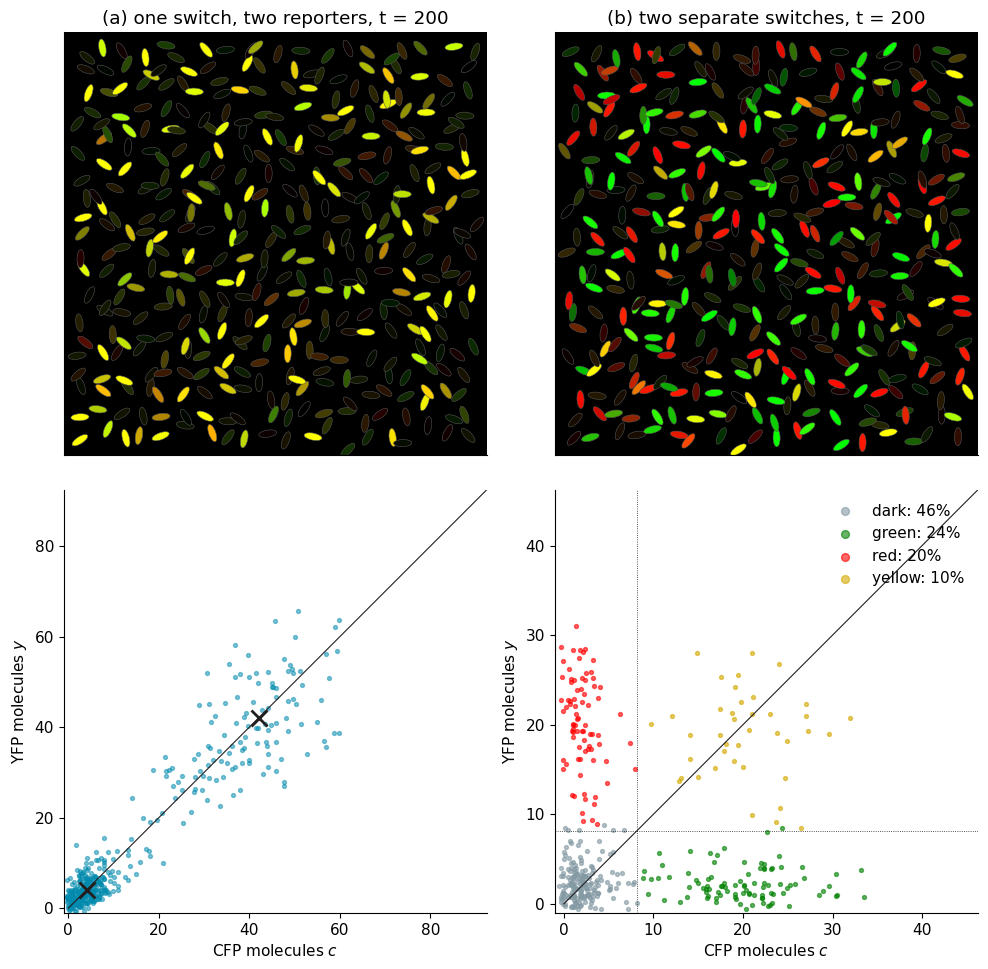

t = 200   (a) dark: 0.69   yellow: 0.31
          (b) dark: 0.46   green: 0.24   red: 0.20   yellow: 0.10
          independent switches, each on with p = 0.32:  dark 0.46, green 0.22, red 0.22, yellow 0.10
long-run fraction of time ON of one switch (the V = 10 run above): 0.31


In [21]:
rng = np.random.default_rng(9)
cells_a2 = snapshot(400, rates_a, [N0, round(beta_rep * X_low), round(beta_rep * X_low)], CHANGES_A, 200, rng)
cells_b2 = snapshot(400, rates_b, [N0, N0], CHANGES_B, 200, rng)
c_a2, y_a2 = cells_a2[:, 1], cells_a2[:, 2]
c_b2, y_b2 = cells_b2[:, 0], cells_b2[:, 1]
show_two_circuits(c_a2, y_a2, c_b2, y_b2, 200, rng)

on_a2 = c_a2 + y_a2 > 2 * mid_a
g = groups(c_b2, y_b2, mid_b)
p2 = np.mean(np.concatenate([c_b2 > mid_b, y_b2 > mid_b]))
print(f"t = 200   (a) dark: {np.mean(~on_a2):.2f}   yellow: {np.mean(on_a2):.2f}")
print(f"          (b) " + "   ".join(f"{name}: {np.mean(m):.2f}" for name, m in g.items()))
print(f"          independent switches, each on with p = {p2:.2f}:  dark {(1-p2)**2:.2f}, "
      f"green {p2*(1-p2):.2f}, red {p2*(1-p2):.2f}, yellow {p2*p2:.2f}")
t10, X10 = runs[10]
print(f"long-run fraction of time ON of one switch (the V = 10 run above): {np.mean(X10 > X_mid):.2f}")

- The fraction of switches that are on has grown from about 0.27 to 0.32, close to the fraction
  of time a single switch spends ON in the long run (0.31, from the long run above; the two
  differ by statistical error). From here on it stops changing: every cell
  keeps jumping, but as many switch on as switch off, so the population **stays split** in the
  same proportions.
- (a) is still two groups on the diagonal; (b) is still four groups in the proportions of
  independent switches, now with $p = 0.32$ (about 10% yellow instead of 6%).

### Would waiting longer change anything?

Instead of taking more snapshots, we follow the fraction of switches that are on, $p(t)$, from
$t = 0$ to $t = 1000$: 300 cells with one switch each ($V = 10$), all started OFF.

There is also a prediction to compare with. If we forget the molecules and keep only the two
switching rates measured above, $a = 1/(\text{average stay in OFF})$ and
$b = 1/(\text{average stay in ON})$, the fraction of cells that are ON obeys

$$\frac{dp}{dt} = a\,(1-p) - b\,p ,$$

cells arriving from OFF minus cells leaving ON. This is the equation of Lecture 1 again
(production $a$, removal $a + b$), so starting from $p = 0$:

$$p(t) = p_\infty\left(1 - e^{-(a+b)t}\right), \qquad p_\infty = \frac{a}{a+b}.$$

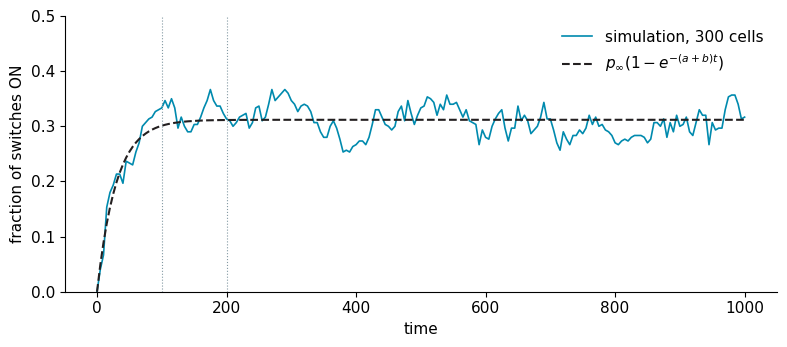

a = 0.0105, b = 0.0232: p_inf = 0.312, time to settle 1/(a+b) = 30
t =  100: p = 0.33
t =  200: p = 0.31
t =  500: p = 0.33
t = 1000: p = 0.32


In [22]:
rng = np.random.default_rng(10)
t = np.arange(0, 1001, 5.0)
X_cells = np.array([gillespie([N0], CHANGES_N, lambda x: rates_switch(x, V), t, rng)[:, 0] / V
                    for _ in range(300)])
p_t = np.mean(X_cells > X_mid, axis=0)           # fraction of cells above the threshold

a_rate, b_rate = 1 / mean_off[1], 1 / mean_on[1]  # measured at V = 10 in "How long does the memory last?"
p_inf = a_rate / (a_rate + b_rate)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(t, p_t, color=BLUE, lw=1.2, label="simulation, 300 cells")
ax.plot(t, p_inf * (1 - np.exp(-(a_rate + b_rate) * t)), color=INK, ls="--",
        label=r"$p_\infty(1 - e^{-(a+b)t})$")
for t_snap in (100, 200):
    ax.axvline(t_snap, color=GREY, lw=0.8, ls=":")
ax.set(xlabel="time", ylabel="fraction of switches ON", ylim=(0, 0.5))
ax.legend(frameon=False); plt.tight_layout(); plt.show()

print(f"a = {a_rate:.4f}, b = {b_rate:.4f}: p_inf = {p_inf:.3f}, time to settle 1/(a+b) = {1/(a_rate + b_rate):.0f}")
for T in (100, 200, 500, 1000):
    print(f"t = {T:4d}: p = {p_t[t == T][0]:.2f}")

The fraction of switches that are ON rises over a few tens of time units and then stays at about
0.3, wobbling only because 300 cells is a finite sample. The two snapshots (dotted lines) were both
taken after it had settled; a snapshot at $t = 1000$ would look the same. **Each cell keeps
jumping for ever, but the population reaches a steady split.** And the two switching rates are
enough to predict it: the dashed curve uses only $a$ and $b$ from the stays.

---
## 3. Why be split? Persisters

### The biology

When a population of bacteria is treated with an antibiotic, most cells die quickly, but a small
fraction survives much longer. These survivors are not resistant mutants: if they are regrown and
treated again, their offspring die just like the original population, with again a small
surviving fraction. They are called **persisters**. Observed cell by cell (Balaban et al.,
*Science*, 2004), persisters are cells that were **growing slowly or not at all** when the drug
came, and they were already there before the drug. A genetically identical population is split
into two kinds of cells.

The idea is **bet-hedging**: antibiotics kill growing cells, and a dormant cell does not grow but
survives. A population that always keeps a few dormant cells loses a little growth in good times,
and survives the bad ones.

### From the switch to two kinds of cells

Suppose that dormancy is controlled by a switch like the one of Section 2: OFF = growing ($G$),
ON = dormant persister ($P$). We do not need the details of the switch, only **how often it
flips**, which is what Section 2 measured:

- $a$ = rate at which a growing cell becomes a persister = 1 / (average stay in OFF);
- $b$ = rate at which a persister wakes up = 1 / (average stay in ON).

Then we count cells instead of molecules. Without drug, growing cells divide at rate $\mu$ and
persisters do not grow; with drug, growing cells are killed at rate $k$ and persisters are not
affected:

$$\text{no drug:}\quad \frac{dG}{dt} = \mu G - aG + bP, \qquad \frac{dP}{dt} = aG - bP,$$

$$\text{drug:}\quad \frac{dG}{dt} = -k G - aG + bP, \qquad \frac{dP}{dt} = aG - bP.$$

Each line is the equation of Lecture 1 (an exponential term) plus cells arriving from the other
state. Time is now in **hours**, and the numbers are illustrative: $\mu = 1$/h (a doubling every
0.7 h), $k = 4$/h, $b = 0.3$/h.

For linear equations like these, `scipy.linalg.expm` gives the exact solution after a time $T$:
a matrix that multiplies the initial numbers of cells. For one equation, $dY/dt = -\alpha Y$, it is
the $e^{-\alpha T}$ of Lecture 1.

In [23]:
mu, kill, b = 1.0, 4.0, 0.3

def A_matrix(a, drug):
    '''The coefficients of the two equations: d(G, P)/dt = A @ (G, P).'''
    growth = -kill if drug else mu
    return np.array([[growth - a, b],
                     [a,          -b]])

def after(v, a, drug, T):
    '''Numbers of (growing, persister) cells after a time T in the given environment.'''
    return expm(A_matrix(a, drug) * T) @ v

def steady_mix(a):
    '''Composition reached after a long time without drug, scaled to one cell in total.'''
    v = np.array([1.0, 0.0])
    for _ in range(50):
        v = after(v, a, drug=False, T=1.0)
        v = v / v.sum()
    return v

for a in [0.01, 0.1]:
    G, P = steady_mix(a)
    print(f"a = {a}/h: fraction of persisters without drug = {P:.4f}")

a = 0.01/h: fraction of persisters without drug = 0.0077
a = 0.1/h: fraction of persisters without drug = 0.0755


### The killing curve

**PREDICT:** a population that has grown for a long time without drug is treated at $t = 0$.
Sketch the number of survivors against time, on a log scale, for $a = 0$ (no persisters) and for
$a = 0.01$/h.

a = 0.0/h: fraction surviving after 2 h = 3.22e-04, after 8 h = 1.27e-14
a = 0.01/h: fraction surviving after 2 h = 6.44e-03, after 8 h = 1.02e-03
a = 0.1/h: fraction surviving after 2 h = 5.99e-02, after 8 h = 1.04e-02


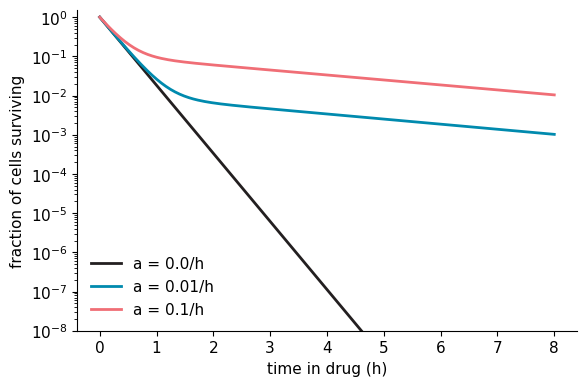

In [24]:
t = np.linspace(0, 8, 200)
fig, ax = plt.subplots(figsize=(6, 4))
for a, col in [(0.0, INK), (0.01, BLUE), (0.1, CORAL)]:
    v0 = steady_mix(a)
    survivors = [after(v0, a, drug=True, T=ti).sum() for ti in t]
    ax.plot(t, survivors, color=col, lw=2, label=f"a = {a}/h")
    print(f"a = {a}/h: fraction surviving after 2 h = {survivors[np.argmin(abs(t - 2))]:.2e}, "
          f"after 8 h = {survivors[-1]:.2e}")
ax.set(yscale="log", ylim=(1e-8, 1.5), xlabel="time in drug (h)", ylabel="fraction of cells surviving")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

Without persisters the curve is a straight line on the log scale: every cell dies at rate
$k + a$, the exponential decay of Lecture 1. With persisters the curve **bends**: a fast first
phase (the growing cells die) and a slow second phase (the persisters, which die only after waking
up, at rate about $b$). This **biphasic killing curve** is how persisters are spotted in the lab,
and the height of the second phase gives roughly the fraction of persisters before the drug.

A random switch between two states, which in Section 2 looked like a nuisance, is here what keeps
the population alive. Whether real persisters use a bistable gene with noise is an active research
question; the point is that noise plus feedback is enough to produce this behaviour.

---
### What we did

- Cell-to-cell differences have two sources: **intrinsic** (each gene's own randomness) and
  **extrinsic** (differences between cells that act on all genes). Two identical reporters in the
  same cell tell them apart: intrinsic noise spreads cells across the diagonal of the CFP-YFP
  plot, extrinsic noise along it.
- $\eta_{\text{int}}^2 = \langle(c-y)^2\rangle/(2\langle c\rangle\langle y\rangle)$ uses the
  difference trick of Lecture 1, and equals $1/\langle c\rangle$ for a Poisson gene (Lecture 2):
  more molecules, less intrinsic noise.
- A **bistable gene with noise** jumps between its two states: identical cells form a
  **bimodal** population, and the memory of Lecture 3 lasts a finite time that grows quickly with
  the number of molecules.
- With two colours, a decision taken by the **cell** (one switch for both) looks like extrinsic
  noise; a decision taken by **each gene** looks like amplified intrinsic noise.
- Being split can pay: **persisters**, cells that switch at random into a dormant state, let a
  population survive a drug; the signature is the biphasic killing curve.